# Por qué medir una prueba: tamaño, potencia y el error de Monte Carlo

- **Nivel:** 1, Fundamentos
- **Requisitos previos:** el tema 01 (los cuadernos que abren un artefacto versionado y leen un `TestResult`)
- **Tiempo de lectura:** unos 30 minutos

## Objetivos

Al terminar este cuaderno puedes:

- decir qué son el tamaño y la potencia de una prueba de validación, y por qué una prueba que nunca se midió sobre datos de verdad conocida es una prueba de tasas de error desconocidas;
- leer un estudio de simulación como sus cinco partes (objetivos, mecanismos generadores de datos, estimandos, métodos y medidas de desempeño) en un artefacto versionado de Contraste;
- tratar una tasa de rechazo como una estimación: dar su error estándar de Monte Carlo y su intervalo de Wilson, y decir cómo se achican con el número de repeticiones;
- distinguir el nivel nominal de una prueba de su tamaño verdadero, y leer la probabilidad de rechazo exacta que no necesita simulación para las pruebas de conteo;
- repetir una fila de simulación versionada desde su semilla y su generador, y obtener el mismo número de rechazos.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.8.1
numpy 2.4.6
matplotlib 3.11.2


## Datos

Los datos son el caso C22 de Contraste, «validar al validador»: el tamaño y la potencia medidos de las pruebas de validación del motor. Nada en él es dato real de una cartera. Cada conjunto se sorteó con un generador de verdad conocida de `riskvalidation.generators` (licencia MIT, clase `generated`), así que la verdad detrás de cada número se conoce exactamente. Este cuaderno lee la familia llamada `null`: cada prueba con valor p, corrida sobre datos donde su hipótesis nula se cumple en la frontera y sus supuestos se satisfacen. Una prueba correcta debería rechazar cerca del 5% de las veces con nivel 5% allí.

- **Archivo que se lee:** `data/derived/C22/null.json`, la clave `outputs` (28 simulaciones, los generadores que las sortearon, las cotas de tamaño) y `provenance`.
- **De dónde viene:** `data-pipeline/pipeline/cases/c22_validator.py` corrió cada simulación una vez, con una semilla escrita junto a su resultado. El cuaderno nunca vuelve a correr las 128.000 repeticiones de la familia; las lee, y repite solo las filas baratas que enseñan.

La celda siguiente carga el artefacto e imprime lo que contiene, con la versión del motor que lo calculó junto a la instalada.

In [2]:
# Cargar la familia nula e indexar sus simulaciones por clave; LANG elige el idioma de las etiquetas bilingües
LANG = "es"
ROOT = Path("../../..").resolve()
null = json.loads((ROOT / "data" / "derived" / "C22" / "null.json").read_text(encoding="utf-8"))
out = null["outputs"]
rows = {row["key"]: row for row in out["simulations"]}

TRUTH = {"synthetic-known-truth": "sintético, verdad conocida"}
print("caso:", null["case_id"], "|", "variante:", null["variant_id"], "|", TRUTH[null["provenance"]["truth_status"]])
print("calculado por riskvalidation", null["provenance"]["riskvalidation_version"], "|", "instalado", rv.__version__)
print("simulaciones:", len(rows), "|", "generadores:", len(out["generators"]))
print("repeticiones en la familia:", sum(row["n_rep"] for row in rows.values()))
print("niveles de las pruebas:", out["levels"])

caso: C22 | variante: null | sintético, verdad conocida
calculado por riskvalidation 0.4.3 | instalado 0.8.1
simulaciones: 28 | generadores: 14
repeticiones en la familia: 128000
niveles de las pruebas: [0.05, 0.01]


## Método

Un estudio de simulación es un experimento, y Morris, White y Crowther (2019) le dan una estructura de reporte llamada ADEMP: **A**ims (objetivos), **D**ata-generating mechanisms (mecanismos generadores de datos), **E**stimands (estimandos), **M**ethods (métodos) y **P**erformance measures (medidas de desempeño). El artefacto de Contraste lleva las cinco:

| Parte | En el artefacto |
|---|---|
| Objetivos | la familia (`null`: ¿cada prueba mantiene su tamaño?) y sus paneles |
| Mecanismos generadores de datos | `generators`, cada uno con su configuración y su `truth` exacta |
| Estimando | la probabilidad de que una prueba rechace al nivel $\alpha$ |
| Métodos | la prueba registrada (`test_id`) bajo la regla de decisión de la política `p<0.05`, `p<0.01` |
| Medidas de desempeño | `rates` (la tasa de rechazo con su error estándar e intervalo), `exact` y `agrees` |

El tamaño de una prueba es su probabilidad de rechazo cuando la hipótesis nula es cierta; la potencia es su probabilidad de rechazo cuando se planta un defecto de severidad conocida. Ambos son probabilidades, así que una simulación solo puede estimarlos. Los pasos siguientes leen una fila del artefacto, tratan su tasa como una estimación, la comparan con el valor exacto donde existe, y la repiten.

### Paso 1: una fila del estudio, leída como ADEMP

La fila `pd.binomial@null` es la prueba binomial sobre una cartera de 1.000 deudores cuya PD de 1% es exactamente correcta. Su generador es `default_counts`, y la `truth` que escribió el generador dice qué son los datos: 10 incumplimientos esperados, una varianza de 9,9 (deudores independientes) y una nula que se cumple en la frontera. La celda siguiente imprime las partes de la fila.

In [3]:
# Leer los objetivos, el generador y su verdad, el método y las medidas de desempeño de una fila
row = rows["pd.binomial@null"]
generator_spec = out["generators"][row["generator"]]
truth = generator_spec["truth"]

print("prueba:", row["test_id"], "|", row["label"][LANG])
print("deudores:", truth["obligors"][0][0], "|", "PD:", truth["pd_true"][0][0], "|", "PD aplicada:", truth["pd_forecast"][0][0])
print("generador:", generator_spec["name"], "| ref:", row["generator"])
print("incumplimientos esperados:", truth["expected_defaults"][0][0], "|", "varianza del conteo:", truth["variance_defaults"][0][0])
print("la nula se cumple en la frontera:", ("sí" if truth["calibration_null_holds"] else "no"))
print("repeticiones:", row["n_rep"], "|", "semilla:", row["seed"])
print("reglas de decisión:", list(row["rates"]))

prueba: pd.binomial | Binomial
deudores: 1000 | PD: 0.01 | PD aplicada: 0.01
generador: default_counts | ref: port-1000-1pct
incumplimientos esperados: 10.0 | varianza del conteo: 9.9
la nula se cumple en la frontera: sí
repeticiones: 4000 | semilla: 3913381310
reglas de decisión: ['p<0.05', 'p<0.01']


### Paso 2: una tasa de rechazo es una estimación

Con $n$ repeticiones y $k$ rechazos, la tasa $\hat r = k/n$ estima la probabilidad de rechazo. Lleva un error estándar de Monte Carlo (Morris, White y Crowther, 2019, Tabla 6, «Rejection %»):

$$\widehat{\mathrm{SE}}(\hat r) = \sqrt{\hat r\,(1-\hat r)/n}$$

y un intervalo. Contraste reporta el intervalo de Wilson, que Brown, Cai y DasGupta (2001) recomiendan para una proporción binomial y que se porta bien cerca de 0, donde viven los tamaños pequeños. La clase `Rate` del motor guarda los conteos y calcula ambos. La celda siguiente construye un `Rate` con los conteos versionados, lo compara con los números que guardó el artefacto, y revisa el error estándar contra su fórmula.

In [4]:
# Construir un Rate con los conteos versionados y compararlo con la tasa, el EE y el intervalo de Wilson guardados
from riskvalidation.harness import Rate

committed = row["rates"]["p<0.05"]
rate = Rate(committed["rejections"], committed["n"])
low, high = rate.interval

print("rechazos:", rate.rejections, "de", rate.n)
print("tasa:", rate.rate, "|", "EE de Monte Carlo:", round(rate.se, 6))
print("intervalo de Wilson:", round(low, 6), "a", round(high, 6))
stored = [committed["rate"], committed["se"], committed["wilson_low"], committed["wilson_high"]]
print("igual a la fila versionada:", ("sí" if np.allclose([rate.rate, rate.se, low, high], stored) else "no"))
print("EE desde la fórmula:", round(float(np.sqrt(rate.rate * (1 - rate.rate) / rate.n)), 6))

rechazos: 182 de 4000
tasa: 0.0455 | EE de Monte Carlo: 0.003295
intervalo de Wilson: 0.039466 a 0.052406
igual a la fila versionada: sí
EE desde la fórmula: 0.003295


### Paso 3: el nivel nominal no es el tamaño

Una prueba de nivel 5% se construye para rechazar a lo sumo el 5% de las veces cuando su nula se cumple. Para una prueba que ve los datos solo a través de un conteo de incumplimientos $D$ de $n$ deudores (las pruebas binomial y de Jeffreys), hay un conteo mínimo $k^*$ cuyo valor p cae bajo $\alpha$, y la prueba rechaza exactamente cuando $D \ge k^*$. Como $D$ es discreto, el tamaño verdadero es la probabilidad de cola del conteo en $k^*$, y rara vez es $\alpha$:

$$P(\text{rechazar}) = P(D \ge k^*), \qquad D \sim \mathrm{Binomial}(n, \pi)$$

El motor encuentra $k^*$ llamando a la propia prueba registrada, así que el valor exacto no necesita simulación y verifica juntos el generador, el arnés y la prueba. La celda siguiente pide el conteo crítico y el tamaño exacto de ambas pruebas al 5% y al 1%, para 1.000 deudores y una PD de 1%.

In [5]:
# Conteo crítico y tamaño exacto de las pruebas binomial y de Jeffreys (n = 1000, PD = 1%)
from riskvalidation.harness import critical_count, rejection_probability

for test in ("pd.binomial", "pd.jeffreys"):
    for alpha in (0.05, 0.01):
        k_star = critical_count(test, 1000, 0.01, alpha)
        exact = rejection_probability(test, 1000, 0.01, alpha)["probability"]
        print(f"{test:12s} nivel {alpha:.2f} | rechaza desde {k_star} incumplimientos | tamaño exacto {exact:.6f}")

print("tamaños exactos versionados, binomial:", rows["pd.binomial@null"]["exact"])
print("tamaños exactos versionados, Jeffreys:", rows["pd.jeffreys@null"]["exact"])

pd.binomial  nivel 0.05 | rechaza desde 16 incumplimientos | tamaño exacto 0.047871
pd.binomial  nivel 0.01 | rechaza desde 19 incumplimientos | tamaño exacto 0.006905
pd.jeffreys  nivel 0.05 | rechaza desde 16 incumplimientos | tamaño exacto 0.047871
pd.jeffreys  nivel 0.01 | rechaza desde 18 incumplimientos | tamaño exacto 0.013833
tamaños exactos versionados, binomial: {'p<0.05': 0.0478705858, 'p<0.01': 0.00690499477}
tamaños exactos versionados, Jeffreys: {'p<0.05': 0.0478705858, 'p<0.01': 0.0138325817}


### Paso 4: ¿concuerda la tasa simulada con el valor exacto?

Cuando existe una probabilidad exacta $p$, la tasa simulada debe concordar con ella dentro de su error de Monte Carlo. La función `agrees` del motor acepta una tasa cuando

$$|\hat r - p| \le z\,\sqrt{p(1-p)/n}, \qquad z = 3{,}29 \ (\text{bilateral } 0{,}1\%)$$

El $z$ ancho es deliberado: el estudio hace decenas de comparaciones así, y un $z$ ajustado marcaría ruido. La celda siguiente llama a `agrees` en las dos pruebas de conteo e imprime al lado la brecha estandarizada, que es la definición del criterio y no una segunda implementación.

In [6]:
# Comparar cada tasa simulada con su probabilidad exacta con agrees, e imprimir la brecha estandarizada
from riskvalidation.harness import agrees

for key in ("pd.binomial@null", "pd.jeffreys@null"):
    for rule in ("p<0.05", "p<0.01"):
        c = rows[key]["rates"][rule]
        simulated = Rate(c["rejections"], c["n"])
        p_exact = rows[key]["exact"][rule]
        gap = (simulated.rate - p_exact) / np.sqrt(p_exact * (1 - p_exact) / simulated.n)
        print(f"{key:18s} {rule:7s} simulada {simulated.rate:.5f} | exacta {p_exact:.5f} | z {gap:+.2f} | concuerda {'sí' if agrees(simulated, p_exact) else 'no'}")

pd.binomial@null   p<0.05  simulada 0.04550 | exacta 0.04787 | z -0.70 | concuerda sí
pd.binomial@null   p<0.01  simulada 0.00600 | exacta 0.00690 | z -0.69 | concuerda sí
pd.jeffreys@null   p<0.05  simulada 0.03900 | exacta 0.04787 | z -2.63 | concuerda sí
pd.jeffreys@null   p<0.01  simulada 0.01125 | exacta 0.01383 | z -1.40 | concuerda sí


### Paso 5: la cota de tamaño, para las pruebas sin valor exacto

La mayoría de las pruebas no tiene probabilidad de rechazo exacta. Para ellas la pregunta es unilateral: ¿es la tasa compatible con un tamaño verdadero de a lo sumo $\alpha$? El motor responde con una cota, $\alpha + z\sqrt{\alpha(1-\alpha)/n}$ con $z = 3{,}09$ (unilateral 0,1%), y `within_size` compara una tasa con ella. El artefacto guarda la cota para sus 4.000 repeticiones. La celda siguiente reproduce la cota guardada y aplica `within_size` a la prueba PSI, que está calibrada, y a la prueba normal en cinco años, que no lo está.

In [7]:
# Reproducir la cota de tamaño guardada y aplicar within_size a dos pruebas
from riskvalidation.harness import size_bound, within_size

for alpha in (0.05, 0.01):
    print(f"nivel {alpha:.2f} | cota para 4000 repeticiones {size_bound(alpha, 4000):.6f} | versionada {out['size_bounds'][f'p<{alpha:.2f}']:.6f}")

for key in ("stability.psi@null", "pd.normal_multiperiod@null"):
    c = rows[key]["rates"]["p<0.05"]
    r = Rate(c["rejections"], c["n"])
    print(f"{key:28s} tasa al 5% {r.rate:.5f} | dentro de la cota {'sí' if within_size(r, 0.05) else 'no'}")

nivel 0.05 | cota para 4000 repeticiones 0.060649 | versionada 0.060649
nivel 0.01 | cota para 4000 repeticiones 0.014862 | versionada 0.014862
stability.psi@null           tasa al 5% 0.05250 | dentro de la cota sí
pd.normal_multiperiod@null   tasa al 5% 0.08375 | dentro de la cota no


### Paso 6: repetir una fila versionada

Todo lo necesario para repetir una fila está en el artefacto: la configuración del generador, la prueba, el número de repeticiones y la semilla. Cada repetición sortea desde su propia corriente, `SeedSequence(seed).spawn(n_rep)`, así que una repetición puede volver a correr sola y la fila entera es exactamente reproducible. La celda siguiente reconstruye el generador desde la configuración versionada, corre `simulate` con la semilla versionada y compara el conteo de rechazos con el artefacto. La fila la calculó un motor más antiguo que el instalado; si la prueba hubiera cambiado, los conteos diferirían, y la celda lo diría.

In [8]:
# Reconstruir el generador desde su configuración versionada y repetir la fila con su semilla versionada
from riskvalidation.generators import DefaultCounts, feed_cell
from riskvalidation.harness import simulate

generator = DefaultCounts(**generator_spec["config"])
replay = simulate(row["test_id"], generator, n_rep=row["n_rep"], seed=row["seed"], feed=feed_cell())

for rule in ("p<0.05", "p<0.01"):
    print(f"{rule} | repetición {replay.rates[rule].rejections} | versionado {row['rates'][rule]['rejections']}")
same = all(replay.rates[r].rejections == row["rates"][r]["rejections"] for r in ("p<0.05", "p<0.01"))
print("idéntica a la fila versionada:", "sí" if same else "no", "|", "calculada por", null["provenance"]["riskvalidation_version"], "|", "instalado", rv.__version__)

p<0.05 | repetición 182 | versionado 182
p<0.01 | repetición 24 | versionado 24
idéntica a la fila versionada: sí | calculada por 0.4.3 | instalado 0.8.1


### Paso 7: el error de Monte Carlo se achica con las repeticiones

Como la repetición $i$ usa siempre la misma corriente, una corrida de 100 repeticiones son las primeras 100 de una de 4.000. Eso da un experimento limpio: el mismo estudio detenido en cuatro largos. El error estándar cae como $1/\sqrt{n}$, así que una corrida 4 veces más larga reduce el intervalo a la mitad. La celda siguiente corre el estudio con 100, 400, 1.600 y 4.000 repeticiones y dibuja cada tasa con su intervalo de Wilson, junto al tamaño exacto y el 5% nominal.

n_rep   100 | tasa 0.0600 | SE 0.0237 | ancho del intervalo 0.0970
n_rep   400 | tasa 0.0425 | SE 0.0101 | ancho del intervalo 0.0403
n_rep  1600 | tasa 0.0500 | SE 0.0054 | ancho del intervalo 0.0214
n_rep  4000 | tasa 0.0455 | SE 0.0033 | ancho del intervalo 0.0129


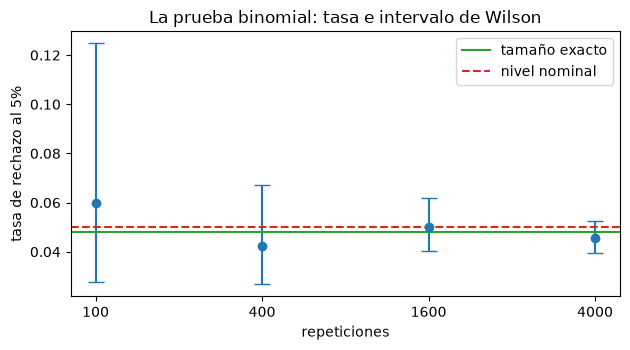

In [9]:
# Correr el mismo estudio en cuatro largos y dibujar cada tasa con su intervalo de Wilson
lengths = (100, 400, 1600, 4000)
fig, ax = plt.subplots(figsize=(6.4, 3.6))
for position, n_rep in enumerate(lengths):
    sim = simulate(row["test_id"], generator, n_rep=n_rep, seed=row["seed"], feed=feed_cell())
    r = sim.rate(0.05)
    low, high = r.interval
    print(f"n_rep {n_rep:5d} | tasa {r.rate:.4f} | SE {r.se:.4f} | ancho del intervalo {high - low:.4f}")
    ax.errorbar(position, r.rate, yerr=[[r.rate - low], [high - r.rate]], fmt="o", capsize=6, color="tab:blue")

ax.axhline(rows["pd.binomial@null"]["exact"]["p<0.05"], color="tab:green", label="tamaño exacto")
ax.axhline(0.05, color="tab:red", linestyle="--", label="nivel nominal")
ax.set_xticks(range(len(lengths)))
ax.set_xticklabels([str(n) for n in lengths])
ax.set_xlabel("repeticiones")
ax.set_ylabel("tasa de rechazo al 5%")
ax.set_title("La prueba binomial: tasa e intervalo de Wilson")
ax.legend()
fig.tight_layout()
plt.show()

## Resultados

- **La fila es un experimento.** `pd.binomial@null` fija sus objetivos (¿la prueba mantiene su tamaño?), su generador (1.000 deudores independientes con PD de 1%, 10 incumplimientos esperados), su método (la prueba registrada con la regla `p<0.05` y `p<0.01`) y sus medidas de desempeño. Nada de esto necesita una cartera real, porque la verdad es la del generador.
- **Una tasa es una estimación.** La prueba binomial rechazó 182 de 4.000 repeticiones al 5%: una tasa de 4,55% con un error estándar de Monte Carlo de 0,33 puntos y un intervalo de Wilson de 3,95% a 5,24%. La clase `Rate` del motor devuelve exactamente los números que guardó el artefacto, y el error estándar coincide con su fórmula.
- **El nivel nominal no es el tamaño.** La prueba binomial rechaza desde 16 incumplimientos con nivel 5%, y la probabilidad de 16 o más incumplimientos es 4,79%, no 5%, porque el conteo es discreto. Con nivel 1% la prueba binomial tiene tamaño exacto 0,69% y la de Jeffreys 1,38%: la prueba de Jeffreys queda sobre su nivel nominal al 1% para esta cartera, sin simulación de por medio.
- **Simulación y valor exacto concuerdan.** La mayor brecha estandarizada de las cuatro comparaciones es -2,63 (la prueba de Jeffreys al 5%), dentro del criterio de 3,29. Una tasa que concuerda con su valor exacto es evidencia de que el generador, el arnés y la prueba están conectados como se pretende.
- **Una cota para el resto.** Con 4.000 repeticiones, un tamaño sobre 6,06% al 5% (1,49% al 1%) no es ruido de Monte Carlo. La prueba PSI queda dentro de la cota con 5,25%; la prueba normal en cinco años queda fuera con 8,38%, una primera señal de que no toda prueba mantiene su tamaño (el cuaderno 02 mide todas).
- **La fila se repite.** Con la semilla versionada la repetición da 182 y 24 rechazos, los conteos versionados, aunque el artefacto lo calculó riskvalidation 0.4.3 y el motor instalado es 0.8.1. Eso dice que la prueba binomial y este generador no cambiaron en esta fila entre las dos versiones; no dice nada de las otras filas.
- **Más repeticiones, un intervalo más angosto.** El intervalo mide 9,7 puntos de ancho con 100 repeticiones, 4,0 con 400, 2,1 con 1.600 y 1,3 con 4.000. Una corrida de 100 repeticiones no distingue una prueba de tamaño 4,8% de una de 6%; con 4.000 se distinguen unas pocas décimas de punto.

Lo que este cuaderno no muestra: la potencia de ninguna prueba (cuaderno 03), el tamaño de las otras veinte pruebas (cuaderno 02), ni qué pasa cuando los incumplimientos de una cartera están correlacionados (cuaderno 04).

## Resumen

- El tamaño de una prueba es su tasa de rechazo cuando su nula se cumple; la potencia es su tasa de rechazo frente a un defecto plantado de severidad conocida. Ambos son probabilidades que una simulación estima.
- Un estudio de simulación reporta sus objetivos, mecanismos generadores de datos, estimando, métodos y medidas de desempeño (ADEMP), y cada fila de Contraste los lleva.
- Una tasa de rechazo tiene un error estándar de Monte Carlo, $\sqrt{\hat r(1-\hat r)/n}$, y un intervalo de Wilson; una tasa sin ellos no se puede leer.
- El nivel nominal no es el tamaño. Para las pruebas de conteo el tamaño exacto no necesita simulación y es el chequeo que la simulación debe pasar.
- Una fila versionada se repite exactamente desde su configuración y su semilla, y una repetición con otra versión del motor se compara con la fila versionada, nombrando ambas versiones.

**Qué probar a continuación.** Repite otra fila de `null.json` desde su semilla (prueba `pd.jeffreys@null` o `stability.psi@null`), y luego lee el cuaderno 02, que mide el tamaño de las veintiuna pruebas.

## Referencias

- Morris, T. P., White, I. R. y Crowther, M. J. (2019), Using simulation studies to evaluate statistical methods, Statistics in Medicine 38(11). https://doi.org/10.1002/sim.8086
- Brown, L. D., Cai, T. T. y DasGupta, A. (2001), Interval estimation for a binomial proportion, Statistical Science 16(2). https://doi.org/10.1214/ss/1009213286
- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, sección 2.5.3.1 (la prueba de Jeffreys). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- Este repositorio: `docs/design/features/c22-validator/requirements.md` (los requisitos que sostienen las mediciones de C22) y `data-pipeline/pipeline/cases/c22_validator.py` (el cálculo que escribió el artefacto).